# FastSpeech 2 text-to-speech - Telugu (IndicTTS)

This notebook trains a multi-speaker FastSpeech 2 text-to-speech model for Telugu, using the PyTorch implementation
[ming024/FastSpeech2](https://github.com/ming024/FastSpeech2) with the modifications described in the project README.
It covers the full pipeline: data selection, pronunciation lexicon, forced alignment, feature extraction, training,
inference on the five test sentences, and the variance-adaptor plots (duration, pitch, energy).

**Data:** [IndicTTS Telugu](https://huggingface.co/datasets/SPRINGLab/IndicTTS_Telugu) (`SPRINGLab/IndicTTS_Telugu`), studio-recorded monolingual Telugu from one male and one female speaker (IndicTTS database, IIT Madras).

**Runtime.** Data preparation (sections 2-11) runs on CPU; training (sections 13-15) needs a GPU. The notebook can be run
with *Runtime -> Run all*: stages that are already complete are skipped, and a stage that fails stops the run.
If the runtime has no GPU, execution stops before training with a message; switching the runtime type to a T4 GPU and
running all cells again continues from there. Prepared data and checkpoints are kept on Google Drive, so a disconnected
session can resume.

## 1. Environment
Checks for a GPU and defines two small helpers: `sh()` runs a shell command and raises on failure, `have()` tests whether files exist.

In [1]:
!nvidia-smi -L || echo 'No GPU in this session'

import os, glob, subprocess, shutil, zipfile

def sh(cmd):
    # run a shell command, stream its output, and raise if it fails
    p = subprocess.Popen(cmd, shell=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                         text=True, bufsize=1, executable='/bin/bash')
    out = []
    for line in p.stdout:
        print(line, end=''); out.append(line)
    if p.wait() != 0:
        raise RuntimeError('Command failed (exit code %d) - see the output above.' % p.returncode)
    return ''.join(out)

def have(pattern):
    return len(glob.glob(pattern)) > 0

os.environ['FS2_WORK'] = '/content/work'
print('helpers ready')

/bin/bash: line 1: nvidia-smi: command not found
No GPU in this session
helpers ready


## 2. Project code
Mounts Google Drive and unpacks `project.zip` (the code, configuration files and pretrained HiFi-GAN vocoder). Prepared data and checkpoints are stored in `fs2_telugu/` on Drive.

In [2]:
from google.colab import drive
drive.mount('/content/drive')
os.chdir('/content')
shutil.rmtree('/content/project', ignore_errors=True)
zipfile.ZipFile('/content/drive/MyDrive/project.zip').extractall('/content')
os.chdir('/content/project')
os.makedirs('/content/drive/MyDrive/fs2_telugu', exist_ok=True)
PREP_TAR = '/content/drive/MyDrive/fs2_telugu/prepared_data.tar'
print('code ready:', os.listdir('/content/project'))

Mounted at /content/drive
code ready: ['Report', 'notebooks', 'English', 'requirements.txt', 'Telugu', 'README.md', 'tests', 'fastspeech2', '.gitignore', 'Results', 'common']


## 3. Python dependencies
Installs the audio, alignment-file and text-processing packages; PyTorch is already part of the Colab image. NLTK data is needed by the grapheme-to-phoneme tool.

In [3]:
sh('pip install -q pyworld tgt g2p-en inflect soundfile librosa pyyaml scikit-learn matplotlib datasets unidecode')
import nltk
for p in ['averaged_perceptron_tagger', 'averaged_perceptron_tagger_eng', 'cmudict']:
    nltk.download(p, quiet=True)
print('ok')

ok


## 4. Montreal Forced Aligner
FastSpeech 2 needs the duration of every phone, which comes from forced alignment of each recording against its transcript.
The Montreal Forced Aligner (MFA) is installed with micromamba in its own environment so it does not interfere with the
Python packages above. The step is skipped when prepared data already exists on Drive.

In [4]:
if os.path.exists(PREP_TAR):
    print('prepared data found on Drive - aligner not needed')
else:
    sh('''
    set -e
    export MAMBA_ROOT_PREFIX=$HOME/micromamba
    if [ ! -f $MAMBA_ROOT_PREFIX/bin/micromamba ]; then
      mkdir -p $MAMBA_ROOT_PREFIX/bin
      curl -Ls https://micro.mamba.pm/api/micromamba/linux-64/latest | tar -xj -C $MAMBA_ROOT_PREFIX bin/micromamba
    fi
    if [ ! -d $MAMBA_ROOT_PREFIX/envs/mfa ]; then
      $MAMBA_ROOT_PREFIX/bin/micromamba create -y -n mfa -c conda-forge python=3.11 montreal-forced-aligner
    fi
    $MAMBA_ROOT_PREFIX/bin/micromamba run -n mfa mfa version
    ''')

prepared data found on Drive - aligner not needed


## 5. Hugging Face access
1. Create a Hugging Face account (or log in).
2. Open https://huggingface.co/datasets/SPRINGLab/IndicTTS_Telugu and accept the conditions if the page asks for it.
3. Create a read token at https://huggingface.co/settings/tokens (*Create new token* -> type **Read**) and paste it in the prompt below.

The token is read through a hidden prompt and is not stored in the notebook.

In [5]:
from getpass import getpass
if os.path.exists(PREP_TAR):
    print('prepared data found on Drive - token not needed')
elif not os.environ.get('HF_TOKEN'):
    os.environ['HF_TOKEN'] = getpass('Hugging Face token: ')
    print('token received, length', len(os.environ['HF_TOKEN']))

prepared data found on Drive - token not needed


## 6. Restore previously prepared data
If a previous session already finished sections 7-10, the prepared data is restored from Drive and those stages are skipped.

In [4]:
tar = PREP_TAR
if not have('/content/work/preprocessed_data/*/train.txt') and os.path.exists(tar):
    os.makedirs('/content/work', exist_ok=True)
    sh('tar -xf ' + tar + ' -C /content')
    print('restored prepared data from Drive')
else:
    print('nothing to restore')

restored prepared data from Drive


## 7. Data selection
Each speaker contributes the same fraction of its audio. Telugu text is converted to phones with a rule-based grapheme-to-phoneme module (`common/telugu_frontend.py`), which also expands numbers, times and ordinals into Telugu words.
Clips shorter than 1 s or longer than the limit set in `config.yaml` are dropped, and the selected clips are split by
utterance into training (~5 h) and validation (~1 h) sets, so no clip appears in both. Audio is resampled to 22.05 kHz mono and
the transcripts are normalised. The per-speaker statistics are written to `selection_stats.json`.

In [7]:
if have('/content/work/preprocessed_data/*/train.txt'):
    print('data already prepared - skipping')
elif have('/content/work/raw_data/*/split.json'):
    print('data already downloaded - skipping')
else:
    sh('python Telugu/preprocess.py --stage select')

data already prepared - skipping


In [8]:
sh('cat /content/work/raw_data/*/selection_stats.json | head -40')

{
  "train_hours": 4.998059780092593,
  "val_hours": 1.0031423900462961,
  "train_utterances": 2245,
  "val_utterances": 459,
  "n_speakers": 2,
  "dropped": {
    "too long": 3221,
    "too short": 12
  },
  "pseudo_speaker_columns": [],
  "pseudo_speaker_keys": {},
  "settings": {
    "train_hours": 5.0,
    "val_hours": 1.0,
    "seed": 1234,
    "min_seconds": 1.0,
    "max_seconds": 15.0,
    "min_speaker_seconds": 60
  },
  "per_speaker": {
    "0": {
      "train_s": 5710.1,
      "val_s": 1149.0,
      "train_n": 639,
      "val_n": 131
    },
    "1": {
      "train_s": 12282.9,
      "val_s": 2462.3,
      "train_n": 1606,
      "val_n": 328
    }
  }
}

'{\n  "train_hours": 4.998059780092593,\n  "val_hours": 1.0031423900462961,\n  "train_utterances": 2245,\n  "val_utterances": 459,\n  "n_speakers": 2,\n  "dropped": {\n    "too long": 3221,\n    "too short": 12\n  },\n  "pseudo_speaker_columns": [],\n  "pseudo_speaker_keys": {},\n  "settings": {\n    "train_hours": 5.0,\n    "val_hours": 1.0,\n    "seed": 1234,\n    "min_seconds": 1.0,\n    "max_seconds": 15.0,\n    "min_speaker_seconds": 60\n  },\n  "per_speaker": {\n    "0": {\n      "train_s": 5710.1,\n      "val_s": 1149.0,\n      "train_n": 639,\n      "val_n": 131\n    },\n    "1": {\n      "train_s": 12282.9,\n      "val_s": 2462.3,\n      "train_n": 1606,\n      "val_n": 328\n    }\n  }\n}'

## 8. Pronunciation lexicon and forced alignment
The lexicon maps every word of the selected transcripts to phones. The aligner is then trained on the selected data and writes
one phone-level TextGrid per utterance. Recipe: MFA's full training pipeline (monophone, triphone, LDA-MLLT and speaker-adaptive stages), the same recipe for both languages so the results are comparable; this is the slowest preparation step (a few hours on CPU). Utterances the aligner cannot align are reported and excluded.

In [9]:
if have('/content/work/preprocessed_data/*/train.txt'):
    print('data already prepared - skipping')
else:
    sh('python Telugu/preprocess.py --stage lexicon')
    if have('/content/work/preprocessed_data/*/TextGrid/*/*.TextGrid'):
        print('alignment already done - skipping')
    else:
        sh('python Telugu/preprocess.py --stage align --num_jobs 4')


===== stage: lexicon =====
lexicon: 12572 words -> /content/work/lexicon.txt

preprocessing stage(s) finished OK

===== stage: align =====
running: /root/micromamba/bin/micromamba run -r /root/micromamba -n mfa mfa train --clean -j 4 --output_directory /content/work/preprocessed_data/IndicTTS_Telugu/TextGrid /content/work/raw_data/IndicTTS_Telugu /content/work/lexicon.txt /content/work/mfa_acoustic_model.zip
 INFO     Setting up corpus information...                                      
 INFO     Loading corpus from source files...                                   
 100% ━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2,704/100  [ 0:00:00 < 0:00:00 , 1,227 it/s ]
 INFO     Found 2 speakers across 2704 files, average number of utterances per  
          speaker: 1352.0                                                       
 INFO     Initializing multiprocessing jobs...                                  
 WARNING  Number of jobs was specified as 4, but due to only having 2 speakers, 
          MFA will o

## 9. Feature extraction
Computes mel-spectrograms, phoneme-level pitch (F0) and energy, and durations from the alignments. Pitch and energy statistics for normalisation are fitted on the training files only.

In [10]:
if not have('/content/work/preprocessed_data/*/train.txt'):
    sh('python Telugu/preprocess.py --stage features')
sh('cat /content/work/preprocessed_data/*/preprocess_summary.json')


===== stage: features =====
/usr/local/lib/python3.13/dist-packages/pyworld/__init__.py:13: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
Processing Data ...

100%|██████████| 2/2 [08:08<00:00, 244.21s/it]
Utterances kept: 2683, no TextGrid (alignment failed): 21, skipped: 0
Computing statistic quantities ...
Total time: 4.284684706475183 hours
train utterances: 2228, val utterances: 455
after alignment: {"train": {"utterances": 2228, "hours": 3.567, "speakers": 2}, "val": {"utterances": 455, "hours": 0.718, "speakers": 2}}

preprocessing stage(s) finished OK
{
  "train": {
    "utterances": 2228,
    "hours": 3.567,
    "speakers": 2
  },
  "val": {
    "utterances": 455,
    "hours": 0.718,
    "speakers": 2
  }
}

'{\n  "train": {\n    "utterances": 2228,\n    "hours": 3.567,\n    "speakers": 2\n  },\n  "val": {\n    "utterances": 455,\n    "hours": 0.718,\n    "speakers": 2\n  }\n}'

## 10. Back up the prepared data
Archives the prepared data to Drive so that a later session can skip sections 7-9.

In [11]:
import tarfile
files = ['work/preprocessed_data', 'work/lexicon.txt']
for pat in ('split.json', 'selection_stats.json'):
    files += [os.path.relpath(p, '/content') for p in glob.glob('/content/work/raw_data/*/' + pat)]
tmp = '/content/drive/MyDrive/fs2_telugu/prepared_data.tar.part'
with tarfile.open(tmp, 'w') as t:
    for f in files:
        t.add('/content/' + f, arcname=f)
os.replace(tmp, '/content/drive/MyDrive/fs2_telugu/prepared_data.tar')
sh('ls -lh /content/drive/MyDrive/fs2_telugu/')

total 465M
-rw------- 1 root root 465M Nov  4 19:35 prepared_data.tar


'total 465M\n-rw------- 1 root root 465M Nov  4 19:35 prepared_data.tar\n'

## 11. Sanity check
Plays a few of the selected recordings with their transcripts.

In [12]:
import IPython.display as ipd
for w in sorted(glob.glob('/content/work/raw_data/*/*/*.wav'))[::700][:4]:
    print(w); print(open(w[:-4] + '.lab', encoding='utf-8').read()); ipd.display(ipd.Audio(w))

/content/work/raw_data/IndicTTS_Telugu/0/0_000000.wav
నరకవాసి.



/content/work/raw_data/IndicTTS_Telugu/0/0_003454.wav
ఇందుకు జిరాఫీ మనం ఇలా ఉండాలని దేవుడే ఉద్దేశించినప్పుడు ఇక చేయగలదేముంది అనుభవించటం తప్ప అని వేదాంతపరంగా మాటాడింది.



/content/work/raw_data/IndicTTS_Telugu/1/1_005431.wav
కుణాళుడు అడవి చేరేసరికి మిట్ట మధ్యాహ్నమయింది, అడవిలో నీడగా, చల్లగా ఉంటుంది ఎండవేడి తగ్గేదాకా ఆడుతూ పాడుతూ అడవిలోనే నడిచే ఉద్దేశంతో కుణాళుడు అడవిలోకి ప్రవేశించబోయాడు.



/content/work/raw_data/IndicTTS_Telugu/1/1_007362.wav
గ్రామస్థుల కధనం ప్రకారం, శివరాంపురానికి చెందిన నారిపెద్ది, వెంకటసుబ్బయ్యకు, నలుగురు కుమారులు ఉన్నారు.



## 12. GPU check
Training requires a GPU. If the session has none, execution stops here; the prepared data is already saved.

In [9]:
import torch
if not torch.cuda.is_available():
    raise RuntimeError('Data preparation is complete and saved to Drive. No GPU in this session, so stopping before training. '
                       'Switch the runtime type to a T4 GPU (Runtime > Change runtime type) and run all cells again; completed stages are skipped.')
print('GPU available:', torch.cuda.get_device_name(0))

GPU available: Tesla T4


## 13. Smoke test
Runs 30 training steps and one validation pass to confirm that the data, model and loss are wired up correctly. Skipped when a training run already exists.

In [10]:
if os.path.exists('/content/drive/MyDrive/fs2_telugu/ckpt/resume.pth.tar'):
    print('training already started earlier - skipping the smoke test')
else:
    shutil.rmtree('/content/work/ckpt', ignore_errors=True); shutil.rmtree('/content/work/log', ignore_errors=True)
    sh('python Telugu/train.py --total_step 30 --plots_dir /tmp/testplots')
    shutil.rmtree('/content/work/ckpt', ignore_errors=True); shutil.rmtree('/content/work/log', ignore_errors=True)

parameters: 35.1 M, device: cuda
starting from scratch
VALIDATION step 30  total 9.819 (mel 4.407 postnet 2.617 pitch 1.032 energy 1.141 dur 0.622)
  new best validation loss -> best_model_fp16.pth
saved checkpoint at step 30 (final)
finished at step 30
no /content/work/log/train_loss.csv
wrote /tmp/testplots/validation_loss.png


## 14. Training
30,000 steps, batch size 16 (see `config.yaml`). Losses are logged to CSV every 50 steps and the validation loss is computed on the full
validation set every 500 steps. Checkpoints go to Drive and the run resumes automatically; the cell stops after 170 minutes
to stay within the Colab session limit and can simply be run again to continue. The best model (lowest validation loss) is kept separately.

In [ ]:
import re
for d in ('ckpt', 'log'):
    target = '/content/drive/MyDrive/fs2_telugu/' + d
    os.makedirs(target, exist_ok=True)
    link = '/content/work/' + d
    if not os.path.islink(link):
        if os.path.exists(link):
            shutil.rmtree(link)
        os.symlink(target, link)
out = sh('python Telugu/train.py --max_minutes 170')
m = re.findall(r'finished at step (\d+)', out)
TOTAL = 30000
if not m or int(m[-1]) < TOTAL:
    raise RuntimeError('Training paused at step %s of %d (session time limit). Re-run this cell to resume.' % (m[-1] if m else '?', TOTAL))
print('training finished')

parameters: 35.1 M, device: cuda
starting from scratch
step 50/30000  loss 13.371 (mel 4.667 postnet 4.419 pitch 1.484 energy 1.561 dur 1.240)
step 100/30000  loss 9.561 (mel 3.711 postnet 3.271 pitch 1.115 energy 1.159 dur 0.305)
step 150/30000  loss 7.034 (mel 2.569 postnet 2.229 pitch 1.022 energy 1.012 dur 0.201)
step 200/30000  loss 5.532 (mel 1.833 postnet 1.615 pitch 0.992 energy 0.929 dur 0.164)
step 250/30000  loss 4.935 (mel 1.513 postnet 1.440 pitch 0.976 energy 0.862 dur 0.145)
step 300/30000  loss 4.535 (mel 1.280 postnet 1.320 pitch 0.964 energy 0.836 dur 0.134)
step 350/30000  loss 4.252 (mel 1.145 postnet 1.260 pitch 0.933 energy 0.792 dur 0.122)
step 400/30000  loss 4.220 (mel 1.126 postnet 1.237 pitch 0.945 energy 0.792 dur 0.119)
step 450/30000  loss 4.032 (mel 1.065 postnet 1.160 pitch 0.916 energy 0.783 dur 0.108)
step 500/30000  loss 4.000 (mel 1.050 postnet 1.141 pitch 0.923 energy 0.777 dur 0.109)
VALIDATION step 500  total 3.862 (mel 1.028 postnet 1.095 pitch 0

## 15. Inference and plots
Synthesises the five test sentences with the best checkpoint and saves the audio, the predicted duration / pitch (F0) / energy
per phone for each sentence, the mel-spectrograms, and the training and validation loss curves to `Results/Telugu/`.

In [6]:
for d in ('ckpt', 'log'):
    target = '/content/drive/MyDrive/fs2_telugu/' + d
    link = '/content/work/' + d
    if not os.path.islink(link):
        if os.path.exists(link):
            shutil.rmtree(link)
        os.symlink(target, link)
print(os.listdir('/content/work/ckpt'))

['best_model_fp16.pth', 'last_model_fp16.pth', 'resume.pth.tar']


In [7]:
sh('python Telugu/inference.py --checkpoint best --all_speakers')
sh('python Telugu/train.py --plots_only --plots_dir /content/project/Results/Telugu')

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
checkpoint: /content/work/ckpt/best_model_fp16.pth
Removing weight norm...
main speaker: 1 (id 1); 2 speakers in model
T1: 66 phones, 4.57 s
T2a: 31 phones, 2.09 s
T2b: 37 phones, 2.37 s
T3: 31 phones, 1.97 s
T4: 120 phones, 7.57 s
done. audio -> /content/project/Results/Telugu/test_generated_audios | plots -> /content/project/Results/Telugu/variance_adaptor_plots
wrote /content/project/Results/Telugu/training_loss.png
wrote /content/project/Results/Telugu/validation_loss.png


'wrote /content/project/Results/Telugu/training_loss.png\nwrote /content/project/Results/Telugu/validation_loss.png\n'

In [10]:
sh('python Telugu/inference.py --checkpoint last --out_dir /content/project/Results/Telugu_last')
import IPython.display as ipd
for w in sorted(glob.glob('/content/project/Results/Telugu_last/test_generated_audios/*.wav')):
    print(w.split('/')[-1]); ipd.display(ipd.Audio(w))

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
checkpoint: /content/work/ckpt/last_model_fp16.pth
Removing weight norm...
main speaker: 1 (id 1); 2 speakers in model
T1: 66 phones, 4.78 s
T2a: 31 phones, 2.10 s
T2b: 37 phones, 2.31 s
T3: 31 phones, 1.89 s
T4: 120 phones, 7.66 s
done. audio -> /content/project/Results/Telugu_last/test_generated_audios | plots -> /content/project/Results/Telugu_last/variance_adaptor_plots
T1.wav


T2a.wav


T2b.wav


T3.wav


T4.wav


In [8]:
import IPython.display as ipd
for w in sorted(glob.glob('/content/project/Results/Telugu/test_generated_audios/*.wav')):
    print(w.split('/')[-1]); ipd.display(ipd.Audio(w))

T1.wav


T2a.wav


T2b.wav


T3.wav


T4.wav


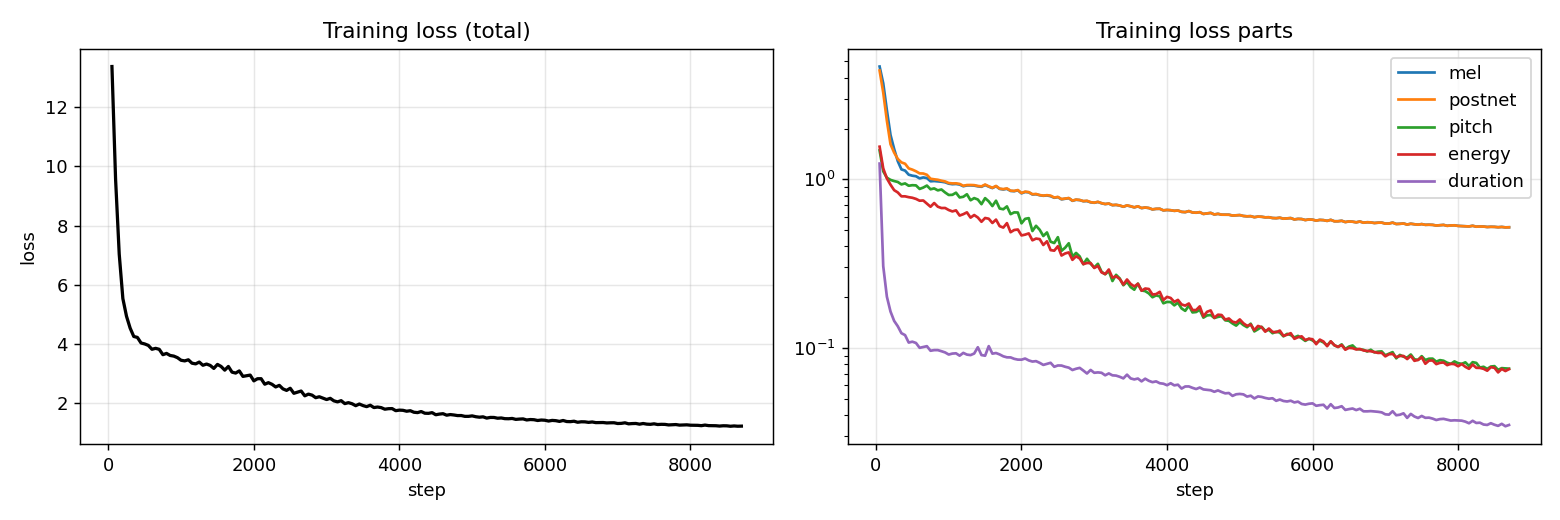

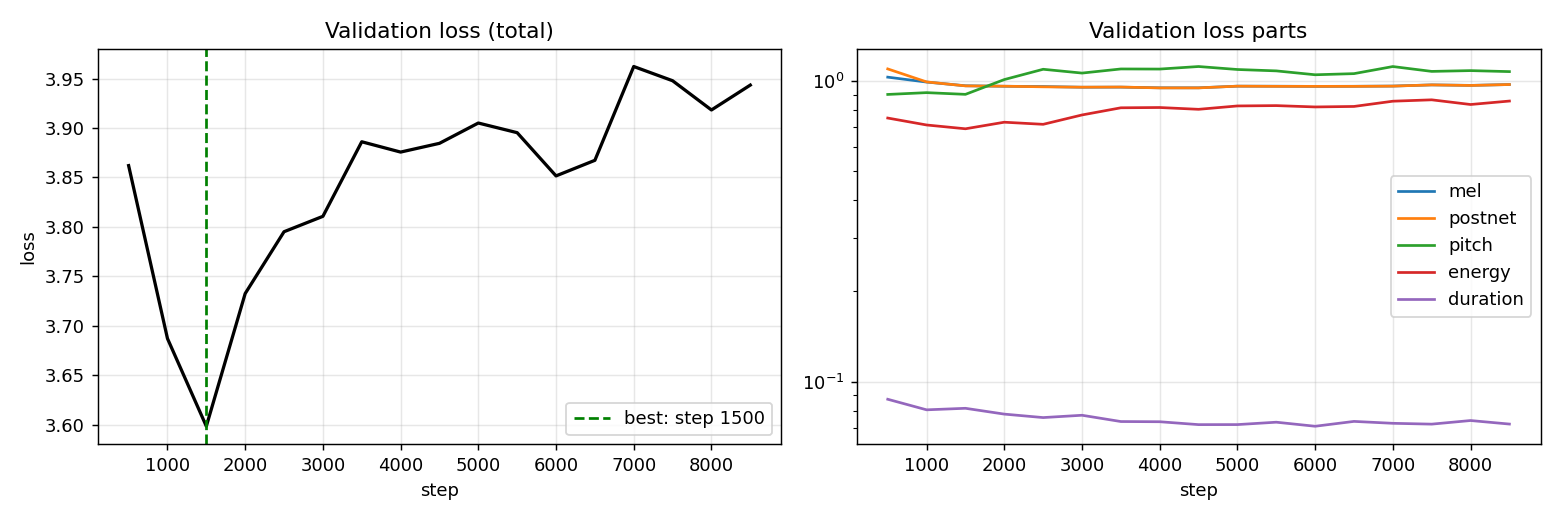

In [9]:
from IPython.display import Image, display
for p in ['training_loss.png', 'validation_loss.png']:
    display(Image('/content/project/Results/Telugu/' + p))

## 16. Additional experiment
Telugu number / time normalisation off for T4 (the sentence containing 2026, 12వ and 10:45), to show what the rule-based
normaliser contributes.

In [ ]:
sh('python Telugu/inference.py --checkpoint best --no_normalize --out_dir /content/project/Results/Telugu/extra/no_normalisation')

## 17. Export
Copies the checkpoints (fp16 weights, ~70 MB each), the dataset statistics and the loss logs next to the results, and writes two archives to Drive.

In [ ]:
os.makedirs('/content/project/Telugu/checkpoints', exist_ok=True)
for f in ('best_model_fp16.pth', 'last_model_fp16.pth'):
    shutil.copy('/content/drive/MyDrive/fs2_telugu/ckpt/' + f, '/content/project/Telugu/checkpoints/' + f)
for f in glob.glob('/content/work/preprocessed_data/*/preprocess_summary.json') + glob.glob('/content/work/raw_data/*/selection_stats.json'):
    shutil.copy(f, '/content/project/Results/Telugu/')
shutil.copy('/content/work/log/train_loss.csv', '/content/project/Results/Telugu/')
shutil.copy('/content/work/log/val_loss.csv', '/content/project/Results/Telugu/')
shutil.make_archive('/content/drive/MyDrive/Telugu_results', 'zip', '/content/project', 'Results/Telugu')
shutil.make_archive('/content/drive/MyDrive/Telugu_checkpoints', 'zip', '/content/project', 'Telugu/checkpoints')
print('saved: Telugu_results.zip and Telugu_checkpoints.zip (in My Drive)')

In [ ]:
R = '/content/project/Results/Telugu'; C = R + '/extra/checkpoint_comparison'
for name, ck in (('best_val_loss', 'best'), ('last_step30000', 'last')):
    sh('python Telugu/inference.py --checkpoint %s --out_dir %s/%s' % (ck, C, name))
    sh('python Telugu/inference.py --checkpoint %s --no_normalize --out_dir %s/%s/extra_no_normalisation' % (ck, C, name))
import pandas as pd
va = pd.read_csv('/content/work/log/val_loss.csv'); print('best validation step:', int(va.loc[va.iloc[:, 1].idxmin(), 'step']))

In [ ]:
import json, IPython.display as ipd
txt = {s['id']: s['text'] for s in json.load(open('/content/project/Telugu/test_sentences.json'))['sentences']}
for sid in txt:
    print(sid, txt[sid])
    for name in ('best_val_loss', 'last_step30000'):
        print('  ', name); ipd.display(ipd.Audio(C + '/' + name + '/test_generated_audios/' + sid + '.wav'))

In [ ]:
import soundfile as sf, matplotlib.pyplot as plt
fig, ax = plt.subplots(len(txt), 2, figsize=(12, 2.2 * len(txt)))
for i, sid in enumerate(txt):
    for j, (name, title) in enumerate((('best_val_loss', 'lowest val loss'), ('last_step30000', 'step 30000 (final)'))):
        x, sr = sf.read(C + '/' + name + '/test_generated_audios/' + sid + '.wav')
        ax[i, j].specgram(x, NFFT=1024, Fs=sr, noverlap=768, cmap='magma'); ax[i, j].set_title(sid + ' - ' + title, fontsize=9)
plt.tight_layout(); plt.savefig(R + '/checkpoint_comparison.png', dpi=110); plt.show()

In [ ]:
open('/content/project/Telugu/diag_check.py', 'w').write(code)
sh('python Telugu/diag_check.py --lang_dir /content/project/Telugu --checkpoint last --out_dir /content/project/Results/Telugu/extra/diagnostics')

In [ ]:
import re, torch, soundfile as sf
from transformers import pipeline
asr = pipeline('automatic-speech-recognition', model='openai/whisper-small', device=0 if torch.cuda.is_available() else -1)
def chars(t): return re.sub(r'[\s\.,!?;:\-"\'()]+', '', t)
def cer(r, h):
    r, h = chars(r), chars(h); d = list(range(len(h) + 1))
    for i in range(1, len(r) + 1):
        p, d[0] = d[0], i
        for j in range(1, len(h) + 1):
            p, d[j] = d[j], min(d[j] + 1, d[j - 1] + 1, p + (r[i - 1] != h[j - 1]))
    return min(d[len(h)] / max(len(r), 1), 1.0)
def hear(path):
    x, sr = sf.read(path)
    return asr({'array': x.astype('float32'), 'sampling_rate': sr},
               generate_kwargs={'language': 'telugu', 'task': 'transcribe', 'max_new_tokens': 80})['text']
print('--- test sentences')
for name in ('best_val_loss', 'last_step30000'):
    sc = []
    for sid in txt:
        h = hear(C + '/' + name + '/test_generated_audios/' + sid + '.wav'); sc.append(cer(txt[sid], h))
        print(name, sid, 'CER %.2f' % sc[-1], '|', h.strip()[:70])
    print(name, 'mean CER %.2f' % (sum(sc) / len(sc)))
D = R + '/extra/diagnostics'; tx = json.load(open(D + '/texts.json'))
print('--- diagnostic (gt = real audio, teacher = true durations/pitch/energy, predicted = normal TTS)')
for key in tx:
    for tag in ('gt', 'teacher', 'predicted'):
        h = hear('%s/%s_%s.wav' % (D, key, tag)); print(key, tag, 'CER %.2f' % cer(tx[key], h), '|', h.strip()[:60])

In [ ]:
import numpy as np, pyworld as pw
for name in ('best_val_loss', 'last_step30000'):
    print('==', name, '\nid   sec   F0 mean(Hz)   F0 std   voiced%')
    for sid in txt:
        x, sr = sf.read(C + '/' + name + '/test_generated_audios/' + sid + '.wav')
        x = x.astype('float64'); f0, t = pw.dio(x, sr); f0 = pw.stonemask(x, f0, t, sr); v = f0[f0 > 0]
        print(sid, '%.2f' % (len(x) / sr), '%.0f' % v.mean(), '%.0f' % v.std(), '%.0f' % (100 * len(v) / len(f0)))

In [ ]:
tr = pd.read_csv('/content/work/log/train_loss.csv')
print(va.columns.tolist()); print('best validation row:'); print(va.loc[va.iloc[:, 1].idxmin()])
print('final validation row:'); print(va.iloc[-1]); print('final train row:'); print(tr.iloc[-1])

In [ ]:
os.makedirs('/content/project/Telugu/checkpoints', exist_ok=True)
for f in ('best_model_fp16.pth', 'last_model_fp16.pth'):
    shutil.copy('/content/drive/MyDrive/fs2_telugu/ckpt/' + f, '/content/project/Telugu/checkpoints/' + f)
for f in glob.glob('/content/work/preprocessed_data/*/preprocess_summary.json') + glob.glob('/content/work/raw_data/*/selection_stats.json'):
    shutil.copy(f, '/content/project/Results/Telugu/')
shutil.copy('/content/work/log/train_loss.csv', '/content/project/Results/Telugu/')
shutil.copy('/content/work/log/val_loss.csv', '/content/project/Results/Telugu/')
shutil.make_archive('/content/drive/MyDrive/Telugu_results', 'zip', '/content/project', 'Results/Telugu')
shutil.make_archive('/content/drive/MyDrive/Telugu_checkpoints', 'zip', '/content/project', 'Telugu/checkpoints')
print('saved: Telugu_results.zip and Telugu_checkpoints.zip (in My Drive)')

/usr/local/lib/python3.13/dist-packages/pyworld/__init__.py:13: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


==== 1/5 diagnostic
/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
Removing weight norm...
val0: బాబూ ఇది పద్మం కాదు అసిధారా చక్రం అన్నాడు నరకవాసి.
val1: నీకు వచ్చిన లోటేమిటి అన్ని ఏర్పాట్లు అయ్యాక పెళ్ళి ఎట్లా ఆగుతుంది నన్ను వేధించకు అన్నాడు లోహితుడు.
val2: జాతకాలను నమ్మటానికి లేదు బ్రహ్మ ఎవరికి ఎంత ఆయుస్సు ఇచ్చాడో ఏ జ్యోతిష్కుడు చెప్పలేడు అన్నారు బంధువులు.
train0: నరకవాసి.
train1: ఆయనను చూడగానే మిత్రవిందకుడు ఏడుస్తూ స్వామీ కరుణించండి ఈ చక్రంనన్నెప్పుడు వదులుతుందో చెప్పండి అని వేడుకున్నాడు.
train2: స్వర్ణ కారుడు.
written to /content/project/Results/Telugu/extra/diagnostics

==== 2/5 intelligibility: character error rate (0 = perfect, 1 = nothing recognised)


config.json:   0%|          | 0.00/1.97k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  967MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

... (61 outputs left out)

[transformers] Both `max_new_tokens` (=80) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


train2 teacher CER 1.00 | स्वरना कारूदू


[transformers] Both `max_new_tokens` (=80) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


train2 predicted CER 1.00 | स्वरन्ना कारूदू

==== 3/5 pitch and speed
best (step 1500) 
id   sec   F0 mean(Hz)   F0 std   voiced%
T1 4.57 199 25 90
T2a 2.09 199 24 74
T2b 2.37 194 29 80
T3 1.97 216 32 86
T4 7.57 200 19 95
last (step 8000) 
id   sec   F0 mean(Hz)   F0 std   voiced%
T1 4.78 189 36 85
T2a 2.10 187 29 82
T2b 2.31 187 30 75
T3 1.89 210 41 83
T4 7.66 191 30 93


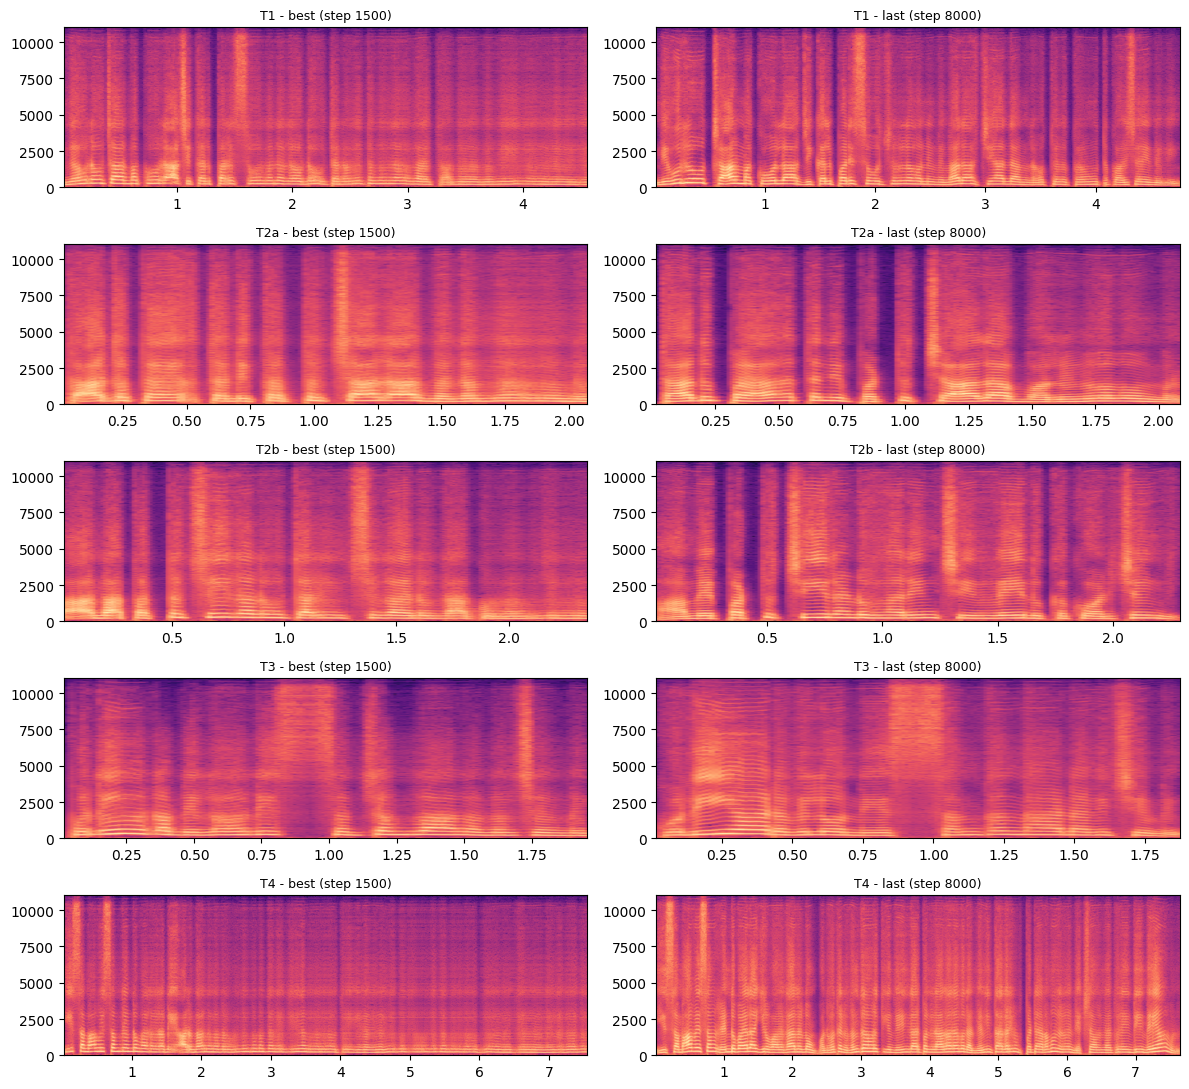


==== 5/5 loss summary
best validation row:
step        1500.00000
total          3.59857
mel            0.96225
postnet        0.96140
pitch          0.90106
energy         0.69232
duration       0.08154
seconds     1029.00000
Name: 2, dtype: float64
final validation row:
step        8500.00000
total          3.94338
mel            0.97132
postnet        0.97140
pitch          1.07235
energy         0.85605
duration       0.07227
seconds     5825.00000
Name: 16, dtype: float64
final train row:
step        8700.00000
total          1.22348
mel            0.51941
postnet        0.51913
pitch          0.07528
energy         0.07478
duration       0.03488
seconds     5959.00000
Name: 173, dtype: float64


In [11]:
import os, re, json, glob, shutil, torch, numpy as np, pandas as pd, soundfile as sf, pyworld as pw
import matplotlib.pyplot as plt
from transformers import pipeline
R = '/content/project/Results/Telugu'
DIRS = {'best (step 1500)': R + '/test_generated_audios', 'last (step 8000)': '/content/project/Results/Telugu_last/test_generated_audios'}
txt = {s['id']: s['text'] for s in json.load(open('/content/project/Telugu/test_sentences.json'))['sentences']}

# ---------- 1/5 diagnostic on real clips (uses the last checkpoint) ----------
code = r"""
import os, sys, json, argparse
ap = argparse.ArgumentParser()
ap.add_argument('--lang_dir', required=True); ap.add_argument('--checkpoint', default='last')
ap.add_argument('--out_dir', required=True); ap.add_argument('--n', type=int, default=3)
a = ap.parse_args()
ROOT = os.path.dirname(a.lang_dir.rstrip('/'))
sys.path.insert(0, ROOT)
from common.configio import load_config, setup_paths
setup_paths()
import numpy as np, torch
from scipy.io import wavfile
from torch.utils.data import DataLoader
cfg, configs = load_config(os.path.join(a.lang_dir, 'config.yaml'))
pre, mod, tr = configs
from dataset import Dataset
from model import FastSpeech2
from utils.model import get_vocoder, vocoder_infer
from utils.tools import to_device
from common import synth
dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ck = a.checkpoint
if ck in ('best', 'last'):
    ck = os.path.join(tr['path']['ckpt_path'], '%s_model_fp16.pth' % ck)
model = FastSpeech2(pre, mod).to(dev); synth.load_weights(model, ck, dev)
voc = get_vocoder(mod, dev)
sr = pre['preprocessing']['audio']['sampling_rate']; hop = pre['preprocessing']['stft']['hop_length']
os.makedirs(a.out_dir, exist_ok=True)
info = {}; bs = tr['optimizer']['batch_size']
for split in ('val', 'train'):
    ds = Dataset(split + '.txt', pre, tr, sort=False, drop_last=False)
    loader = DataLoader(ds, batch_size=bs * 4, shuffle=False, collate_fn=ds.collate_fn)
    batch = to_device(next(iter(loader))[0], dev)
    (ids, raw, spk, texts, src_lens, max_src, mels, mel_lens, max_mel, pit, ene, dur) = batch
    with torch.no_grad():
        tf = model(*batch[2:])
    for i in range(min(a.n, len(ids))):
        L = int(src_lens[i]); T = int(mel_lens[i])
        def wav(mel, frames):
            return vocoder_infer(mel.unsqueeze(0).transpose(1, 2), voc, mod, pre, lengths=[frames * hop])[0]
        with torch.no_grad():
            pr = model(spk[i:i + 1], texts[i:i + 1, :L], src_lens[i:i + 1], L)
        pm = int(pr[9][0])
        for tag, w in (('gt', wav(mels[i, :T], T)), ('teacher', wav(tf[1][i, :T], T)), ('predicted', wav(pr[1][0, :pm], pm))):
            wavfile.write(os.path.join(a.out_dir, '%s%d_%s.wav' % (split, i, tag)), sr, w)
        info['%s%d' % (split, i)] = raw[i]; print('%s%d: %s' % (split, i, raw[i]))
json.dump(info, open(os.path.join(a.out_dir, 'texts.json'), 'w'), ensure_ascii=False, indent=1)
print('written to', a.out_dir)
"""
open('/content/project/Telugu/diag_check.py', 'w').write(code)
D = R + '/extra/diagnostics'
print('==== 1/5 diagnostic'); sh('python Telugu/diag_check.py --lang_dir /content/project/Telugu --checkpoint last --out_dir ' + D)

# ---------- 2/5 intelligibility (character error rate) ----------
print('\n==== 2/5 intelligibility: character error rate (0 = perfect, 1 = nothing recognised)')
asr = pipeline('automatic-speech-recognition', model='openai/whisper-small', device=0 if torch.cuda.is_available() else -1)
def chars(t): return re.sub(r'[\s\.,!?;:\-"\'()]+', '', t)
def cer(r, h):
    r, h = chars(r), chars(h); d = list(range(len(h) + 1))
    for i in range(1, len(r) + 1):
        p, d[0] = d[0], i
        for j in range(1, len(h) + 1):
            p, d[j] = d[j], min(d[j] + 1, d[j - 1] + 1, p + (r[i - 1] != h[j - 1]))
    return min(d[len(h)] / max(len(r), 1), 1.0)
def hear(path):
    x, sr = sf.read(path)
    return asr({'array': x.astype('float32'), 'sampling_rate': sr}, generate_kwargs={'language': 'telugu', 'task': 'transcribe', 'max_new_tokens': 80})['text']
for name, d in DIRS.items():
    sc = []
    for sid in txt:
        h = hear(d + '/' + sid + '.wav'); sc.append(cer(txt[sid], h)); print(name, sid, 'CER %.2f' % sc[-1], '|', h.strip()[:60])
    print('>>', name, 'mean CER %.2f' % (sum(sc) / len(sc)))
tx = json.load(open(D + '/texts.json'))
print('-- diagnostic: gt = real audio, teacher = model given true durations/pitch/energy, predicted = normal text-to-speech')
for key in tx:
    for tag in ('gt', 'teacher', 'predicted'):
        h = hear('%s/%s_%s.wav' % (D, key, tag)); print(key, tag, 'CER %.2f' % cer(tx[key], h), '|', h.strip()[:50])

# ---------- 3/5 pitch and speed ----------
print('\n==== 3/5 pitch and speed')
for name, d in DIRS.items():
    print(name, '\nid   sec   F0 mean(Hz)   F0 std   voiced%')
    for sid in txt:
        x, sr = sf.read(d + '/' + sid + '.wav'); x = x.astype('float64')
        f0, t = pw.dio(x, sr); f0 = pw.stonemask(x, f0, t, sr); v = f0[f0 > 0]
        print(sid, '%.2f' % (len(x) / sr), '%.0f' % v.mean(), '%.0f' % v.std(), '%.0f' % (100 * len(v) / len(f0)))

# ---------- 4/5 side-by-side spectrograms ----------
fig, ax = plt.subplots(len(txt), 2, figsize=(12, 2.2 * len(txt)))
for i, sid in enumerate(txt):
    for j, (name, d) in enumerate(DIRS.items()):
        x, sr = sf.read(d + '/' + sid + '.wav'); ax[i, j].specgram(x, NFFT=1024, Fs=sr, noverlap=768, cmap='magma'); ax[i, j].set_title(sid + ' - ' + name, fontsize=9)
plt.tight_layout(); plt.savefig(R + '/checkpoint_comparison.png', dpi=110); plt.show()

# ---------- 5/5 loss summary ----------
print('\n==== 5/5 loss summary')
va = pd.read_csv('/content/work/log/val_loss.csv'); tr = pd.read_csv('/content/work/log/train_loss.csv')
print('best validation row:'); print(va.loc[va.iloc[:, 1].idxmin()]); print('final validation row:'); print(va.iloc[-1]); print('final train row:'); print(tr.iloc[-1])

In [12]:
import os, shutil
R = '/content/project/Results'
main, last = R + '/Telugu', R + '/Telugu_last'
dest = main + '/extra/checkpoint_comparison/best_step1500'
os.makedirs(dest, exist_ok=True)
for sub in ('test_generated_audios', 'variance_adaptor_plots'):
    if os.path.exists(f'{main}/{sub}'):
        shutil.rmtree(f'{dest}/{sub}', ignore_errors=True)
        shutil.move(f'{main}/{sub}', f'{dest}/{sub}')
    if os.path.exists(f'{last}/{sub}'):
        shutil.copytree(f'{last}/{sub}', f'{main}/{sub}')
    else:
        print('missing in Telugu_last:', sub)
for r, d, f in os.walk(main):
    print(r.replace(R, ''), len(f), 'files')

/Telugu 4 files
/Telugu/variance_adaptor_plots 5 files
/Telugu/variance_adaptor_plots/energy 5 files
/Telugu/variance_adaptor_plots/duration 5 files
/Telugu/variance_adaptor_plots/pitch 5 files
/Telugu/extra 0 files
/Telugu/extra/checkpoint_comparison 0 files
/Telugu/extra/checkpoint_comparison/best_step1500 0 files
/Telugu/extra/checkpoint_comparison/best_step1500/variance_adaptor_plots 5 files
/Telugu/extra/checkpoint_comparison/best_step1500/variance_adaptor_plots/energy 5 files
/Telugu/extra/checkpoint_comparison/best_step1500/variance_adaptor_plots/duration 5 files
/Telugu/extra/checkpoint_comparison/best_step1500/variance_adaptor_plots/pitch 5 files
/Telugu/extra/checkpoint_comparison/best_step1500/test_generated_audios 5 files
/Telugu/extra/checkpoint_comparison/best_step1500/test_generated_audios/extra_speakers 5 files
/Telugu/extra/diagnostics 19 files
/Telugu/test_generated_audios 5 files


In [13]:
import os, glob, shutil
os.makedirs('/content/project/Telugu/checkpoints', exist_ok=True)
for f in ('best_model_fp16.pth', 'last_model_fp16.pth'):
    shutil.copy('/content/drive/MyDrive/fs2_telugu/ckpt/' + f, '/content/project/Telugu/checkpoints/' + f)
for f in glob.glob('/content/work/preprocessed_data/*/preprocess_summary.json') + glob.glob('/content/work/raw_data/*/selection_stats.json'):
    shutil.copy(f, '/content/project/Results/Telugu/')
shutil.copy('/content/work/log/train_loss.csv', '/content/project/Results/Telugu/')
shutil.copy('/content/work/log/val_loss.csv', '/content/project/Results/Telugu/')
shutil.make_archive('/content/drive/MyDrive/Telugu_results', 'zip', '/content/project', 'Results/Telugu')
shutil.make_archive('/content/drive/MyDrive/Telugu_checkpoints', 'zip', '/content/project', 'Telugu/checkpoints')
print('saved: Telugu_results.zip and Telugu_checkpoints.zip (in My Drive)')

saved: Telugu_results.zip and Telugu_checkpoints.zip (in My Drive)
